# Staining: measure it, normalise it, and check whether the trajectory still holds

**Created 2026-11-09.** Follows `lab_associations_exploratory.ipynb`, which found that the per-patient
*stage-adjusted pseudotime offset* tracks crop darkness (ρ = −0.61) far more than any lab value.

**The problem in one paragraph.** Every smear is stained a little differently (paler, darker, bluer). If the AI model
reads "darker" as "less mature", a patient's whole set of cells shifts along the maturation axis for a technical reason.
But the darkness measure used so far (`stain_darkness`) averages *all* purple pixels in the crop, including the annotated
cell's own nucleus, which genuinely changes with maturation. So it cannot tell slide staining apart from biology.

**What this notebook does**
1. **Measure staining properly**, from material *outside* the annotated cell (neutral non-nuclear material such as red
   cells, the empty background, and neighbouring nuclei), and test whether the offset tracks it.
2. **Normalise colour per slide** (Reinhard colour transfer, statistics taken outside the annotated cells) and re-embed.
3. **Colour-jitter averaging**: embed each cell under 4 random colour perturbations and average (no reference needed).
4. **Re-run the trajectory checks** (S1, S2, S4, V1, V2, V3, size, context) on baseline vs. the two fixes.
5. **Re-run the two lab tests** (WBC vs median pseudotime; WBC vs offset) on each version.

**Files.** Reads existing files only. Writes **two new folders** (created only if absent, never overwritten):
`data/embeddings/dinobloom_b_letterbox_m05_reinhard/` and `data/embeddings/dinobloom_b_letterbox_m05_jitter4/`.
Re-running loads them instead of re-embedding. No downloads: model code from the local torch-hub cache,
weights from `models/DinoBloom-B.pth`.

## A. Plan (written 2026-11-09, before any normalised embedding or result was computed)

**Baseline:** letterbox 5% tight crops (the primary version), DinoBloom-B CLS, Option A pseudotime.

**Part 1 – slide-level stain indices** (per crop, pixels outside the annotated box + 5% margin; per patient = median):
- `ref_L`, `ref_a`, `ref_b`: CIELAB lightness / red–green / blue–yellow of *neutral non-nuclear* pixels
  (not purple, not background, low saturation; mostly red cells, partly plasma/haze — see example figure)
- `bg_L`: lightness of empty background
- `nbr_nuc_L`: lightness of purple pixels outside the box (neighbouring nuclei/cytoplasm; slide stain but also
  influenced by which neighbours are present)
- for contrast, `cell_nuc_L`: lightness of purple pixels *inside* the box (the annotated cell itself)

Report the patient share of variance (R²) of each per-crop index (high = slide-level), and the patient-level
Spearman ρ between the baseline `offset` and each index.
**Rule:** a slide-level stain effect is considered present if |ρ| ≥ 0.3 with p < 0.05 for any of `ref_L`, `ref_b`,
`bg_L`, `nbr_nuc_L`.

**Part 2 – Reinhard normalisation (per patient = per slide).** CIELAB mean and SD per channel from all non-background
pixels *outside the annotated boxes* across that patient's crops; target = cohort median of the per-patient means/SDs
(no single reference slide is chosen). Applied to the whole stored 320 px crop, then letterbox 5% → DinoBloom-B.

**Part 3 – colour-jitter averaging.** 4 draws per cell on the 320 px crop: brightness, contrast, saturation factors
U(0.8, 1.2), hue shift U(−0.03, 0.03); seeds fixed per (draw, cell). CLS embeddings averaged over the 4 draws.

**Part 4 – success criteria for a fix** (decided now, labs not used):
1. All pre-specified checks still pass (S1, S2, S4, V1, V2 monotonic, V3 majority positive).
2. Stage ordering not materially worse: V2 ρ and V3 median within-patient ρ within 0.02 of baseline.
3. |ρ(offset, `stain_darkness`)| and |ρ(offset, strongest Part-1 slide index)| both fall below 0.3.

**Part 5 – labs** (only after Parts 1–4): H1a (WBC vs median pseudotime) and H2-WBC (WBC vs offset) on each version.
Stability grid of the original analysis (9 diffusion maps per version) is omitted here for run time.

In [1]:
import json, time, datetime
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats
from scipy.sparse import csr_matrix, diags
from scipy.sparse.linalg import eigsh
from scipy.sparse.csgraph import connected_components
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EMB = ROOT / "data" / "embeddings"
LAB_CSV = ROOT / "reports" / "CPCML_46_patients_laboratory_values.csv"
BASE = "dinobloom_b_letterbox_m05"
NEW = {"reinhard": EMB / f"{BASE}_reinhard", "jitter4": EMB / f"{BASE}_jitter4"}

STAGES = ["promyelocyte", "neutrophilic_myelocyte", "neutrophilic_metamyelocyte",
          "neutrophilic_band", "segmented_neutrophil"]
SHORT = ["Pro", "Myelo", "Meta", "Band", "Seg"]
PURPLE_THRESHOLD = 35          # same as the original crop-feature definition
PAD_COLOR = (124, 116, 104)    # ImageNet mean -> 0 after normalisation (as in embed_variants.py)
OUT_PX, MARGIN = 224, 0.05
MIN_PX = 300                   # minimum pixels for a per-crop index
N_JITTER = 4

INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#9a9994", "#e4e3df"
BLUE, ORANGE = "#2a78d6", "#eb6834"
STAGE_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.titlesize": 9.5,
                     "axes.titlecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.dpi": 110})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)

cells = pd.read_csv(EMB / "dinobloom_b" / "cells.csv", dtype={"patient_id": str})
feat = pd.read_csv(EMB / "dinobloom_b" / "crop_features_purple35.csv")
assert (feat["embedding_row"].to_numpy() == cells["embedding_row"].to_numpy()).all()
cells = cells.join(feat.drop(columns="embedding_row"))
cells["stage"] = cells["label"].map({s: i for i, s in enumerate(STAGES, 1)})
cells["area_um2"] = cells["bbox_width"] * cells["bbox_height"] * cells["pixel_spacing_um"] ** 2
cells["path"] = [(ROOT / "notebooks" / p).resolve() for p in cells["image_path"]]
N = len(cells)
pid = cells["patient_id"].to_numpy()
stage = cells["stage"].to_numpy()
lowres = cells["resized_from_native"].to_numpy().astype(bool)
area = cells["area_um2"].to_numpy()
print("cells:", N, "| patients:", cells["patient_id"].nunique(), "| all crops exist:",
      all(p.exists() for p in cells["path"][:200]))

cells: 8340 | patients: 46 | all crops exist: True


In [2]:
# Colour utilities (sRGB <-> CIELAB, D65) and the crop geometry used by embed_variants.py
_M = np.array([[0.4124564, 0.3575761, 0.1804375],
               [0.2126729, 0.7151522, 0.0721750],
               [0.0193339, 0.1191920, 0.9503041]])
_MINV = np.linalg.inv(_M)
_WHITE = np.array([0.95047, 1.0, 1.08883])
_D = 6 / 29


def rgb_to_lab(rgb):
    c = np.asarray(rgb, float) / 255.0
    lin = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    t = (lin @ _M.T) / _WHITE
    f = np.where(t > _D ** 3, np.cbrt(t), t / (3 * _D ** 2) + 4 / 29)
    return np.stack([116 * f[..., 1] - 16, 500 * (f[..., 0] - f[..., 1]), 200 * (f[..., 1] - f[..., 2])], -1)


def lab_to_rgb(lab):
    fy = (lab[..., 0] + 16) / 116
    f = np.stack([fy + lab[..., 1] / 500, fy, fy - lab[..., 2] / 200], -1)
    t = np.where(f > _D, f ** 3, 3 * _D ** 2 * (f - 4 / 29)) * _WHITE
    lin = np.clip(t @ _MINV.T, 0, 1)
    c = np.where(lin <= 0.0031308, 12.92 * lin, 1.055 * lin ** (1 / 2.4) - 0.055)
    return np.clip(np.round(c * 255), 0, 255).astype(np.uint8)


_test = np.random.default_rng(0).integers(0, 256, (1000, 3))
assert np.abs(lab_to_rgb(rgb_to_lab(_test)).astype(int) - _test).max() <= 1, "LAB round trip failed"


def box_coords(c):
    s = 320 / c["native_crop_px"]
    return ((c["bbox_x_min"] - c["crop_x"]) * s, (c["bbox_y_min"] - c["crop_y"]) * s,
            (c["bbox_x_max"] - c["crop_x"]) * s, (c["bbox_y_max"] - c["crop_y"]) * s)


def tight_letterbox(img, c, margin=MARGIN):
    x0, y0, x1, y1 = box_coords(c)
    w, h = x1 - x0, y1 - y0
    x0, x1 = max(0, x0 - margin * w), min(320, x1 + margin * w)
    y0, y1 = max(0, y0 - margin * h), min(320, y1 + margin * h)
    cell = img.crop((round(x0), round(y0), round(x1), round(y1)))
    f = OUT_PX / max(cell.size)
    nw, nh = max(1, round(cell.width * f)), max(1, round(cell.height * f))
    cell = cell.resize((nw, nh), Image.Resampling.BICUBIC)
    canvas = Image.new("RGB", (OUT_PX, OUT_PX), PAD_COLOR)
    canvas.paste(cell, ((OUT_PX - nw) // 2, (OUT_PX - nh) // 2))
    return canvas


def masks(a, c):
    # a: HxWx3 int array of the stored 320 px crop
    R, G, B = a[..., 0], a[..., 1], a[..., 2]
    grey = a.mean(-1)
    sat = a.max(-1) - a.min(-1)
    purple = (B - G) > PURPLE_THRESHOLD
    bg = (grey >= 225) & (sat < 20)
    ref = (~purple) & (~bg) & ((B - G) < 18) & (sat < 45) & (grey > 110) & (grey < 225)
    x0, y0, x1, y1 = box_coords(c)
    w, h = x1 - x0, y1 - y0
    inside = np.zeros(grey.shape, bool)
    inside[max(0, int(y0 - MARGIN * h)):int(np.ceil(y1 + MARGIN * h)),
           max(0, int(x0 - MARGIN * w)):int(np.ceil(x1 + MARGIN * w))] = True
    return purple, bg, ref, inside

## 1. Measure staining from outside the annotated cell
One pass over all 8,340 stored crops (a few minutes). The same pass collects the per-patient colour statistics
used for Reinhard normalisation in Part 2.

In [3]:
rows = []
acc = {}   # per patient: sum, sum of squares, count of LAB over non-background pixels outside the box
t0 = time.time()
for i, c in cells.iterrows():
    a = np.asarray(Image.open(c["path"]).convert("RGB")).astype(int)
    lab = rgb_to_lab(a)
    purple, bg, ref, inside = masks(a, c)
    out = ~inside

    def mean_L(m, ch=0):
        return lab[..., ch][m].mean() if m.sum() >= MIN_PX else np.nan

    m_ref = ref & out
    rows.append({"ref_L": mean_L(m_ref), "ref_a": mean_L(m_ref, 1), "ref_b": mean_L(m_ref, 2),
                 "bg_L": mean_L(bg & out), "nbr_nuc_L": mean_L(purple & out),
                 "cell_nuc_L": mean_L(purple & inside), "ref_frac": m_ref.mean(), "bg_frac": (bg & out).mean()})
    tissue = lab[(~bg) & out]
    s = acc.setdefault(c["patient_id"], [np.zeros(3), np.zeros(3), 0])
    s[0] += tissue.sum(0); s[1] += (tissue ** 2).sum(0); s[2] += len(tissue)
    if (i + 1) % 2000 == 0:
        print(f"{i + 1} / {N}  {time.time() - t0:.0f} s")

stain = pd.DataFrame(rows, index=cells.index)
IDX = ["ref_L", "ref_a", "ref_b", "bg_L", "nbr_nuc_L", "cell_nuc_L"]
print("crops with a value:", stain[IDX].notna().sum().to_dict())

2000 / 8340  1014 s


4000 / 8340  2180 s


6000 / 8340  2935 s


8000 / 8340  4506 s


crops with a value: {'ref_L': 7815, 'ref_a': 7815, 'ref_b': 7815, 'bg_L': 7362, 'nbr_nuc_L': 8328, 'cell_nuc_L': 8340}


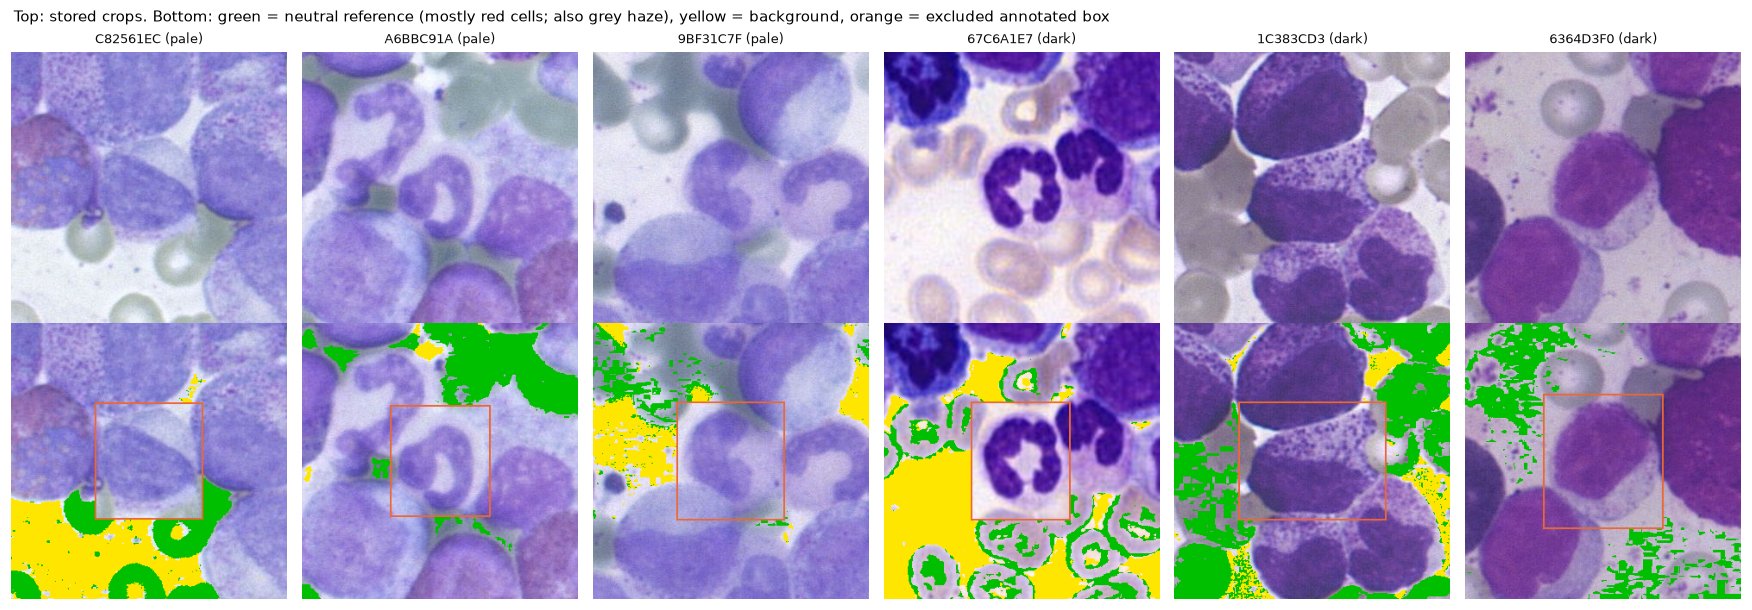

In [4]:
# What the masks pick up: 2 crops each from the 3 palest and 3 darkest patients (by old stain_darkness)
pm = cells.groupby("patient_id")["stain_darkness"].mean().sort_values()
show = list(pm.index[:3]) + list(pm.index[-3:])
fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j, p in enumerate(show):
    c = cells[cells["patient_id"] == p].sample(1, random_state=3).iloc[0]
    a = np.asarray(Image.open(c["path"]).convert("RGB")).astype(int)
    purple, bg, ref, inside = masks(a, c)
    ov = a.copy()
    ov[ref & ~inside] = [0, 190, 0]
    ov[bg & ~inside] = [255, 230, 0]
    ov[inside & ~(np.roll(inside, 2, 0) & np.roll(inside, -2, 0) & np.roll(inside, 2, 1) & np.roll(inside, -2, 1))] = [235, 104, 52]
    axes[0, j].imshow(a.astype(np.uint8)); axes[1, j].imshow(ov.astype(np.uint8))
    axes[0, j].set_title(f"{p[:8]} ({'pale' if j < 3 else 'dark'})", fontsize=8.5)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Top: stored crops. Bottom: green = neutral reference (mostly red cells; also grey haze), "
             "yellow = background, orange = excluded annotated box", x=0.01, ha="left", fontsize=9.5)
plt.tight_layout()
plt.show()

In [5]:
def r2_by_group(values, groups):
    df = pd.DataFrame({"v": np.asarray(values, float), "g": np.asarray(groups)}).dropna()
    gm = df.groupby("g")["v"].transform("mean")
    return 1 - ((df["v"] - gm) ** 2).sum() / ((df["v"] - df["v"].mean()) ** 2).sum()


print("Share of per-crop variance explained by patient (high = slide-level):")
r2 = pd.Series({k: r2_by_group(stain[k], pid) for k in IDX})
r2["stain_darkness (old, includes the cell)"] = r2_by_group(cells["stain_darkness"], pid)
print(r2.round(3).to_string())

S = stain.groupby(pid)[IDX].median()
S["stain_darkness"] = cells.groupby("patient_id")["stain_darkness"].mean()
print("\nPatient-level Spearman correlations between indices:")
S.corr(method="spearman").round(2)

Share of per-crop variance explained by patient (high = slide-level):
ref_L                                      0.436
ref_a                                      0.947
ref_b                                      0.828
bg_L                                       0.600
nbr_nuc_L                                  0.643
cell_nuc_L                                 0.629
stain_darkness (old, includes the cell)    0.711

Patient-level Spearman correlations between indices:


,ref_L,ref_a,ref_b,bg_L,nbr_nuc_L,cell_nuc_L,stain_darkness
ref_L,1.00,-0.10,-0.13,0.12,0.15,0.13,-0.15
ref_a,-0.10,1.00,0.68,-0.13,-0.75,-0.73,0.74
ref_b,-0.13,0.68,1.00,0.26,-0.44,-0.42,0.43
bg_L,0.12,-0.13,0.26,1.00,0.16,0.18,-0.16
nbr_nuc_L,0.15,-0.75,-0.44,0.16,1.00,0.99,-1.00
cell_nuc_L,0.13,-0.73,-0.42,0.18,0.99,1.00,-0.99
stain_darkness,-0.15,0.74,0.43,-0.16,-1.00,-0.99,1.00


In [6]:
def pt_features(pt):
    d = cells[["patient_id", "stage"]].assign(pt=pt)
    d["resid"] = d["pt"] - d["stage"].map(d.groupby("stage")["pt"].median())
    out = pd.DataFrame({"pt_median": d.groupby("patient_id")["pt"].median()})
    ps = d.groupby(["patient_id", "stage"]).agg(n=("pt", "size"), res=("resid", "median"))
    ps = ps[ps["n"] >= 5]
    out["offset"] = ps["res"].groupby(level="patient_id").mean()
    return out


def spearman_ci(x, y, n_boot=2000, seed=0):
    m = x.notna() & y.notna()
    xv, yv = x[m].to_numpy(), y[m].to_numpy()
    n = len(xv)
    rho, p = stats.spearmanr(xv, yv)
    rng = np.random.default_rng(seed)
    boot = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if len(np.unique(xv[i])) > 1 and len(np.unique(yv[i])) > 1:
            boot.append(stats.spearmanr(xv[i], yv[i])[0])
    lo, hi = np.nanpercentile(boot, [2.5, 97.5]) if boot else (np.nan, np.nan)
    return {"n": n, "rho": rho, "ci_lo": lo, "ci_hi": hi, "p": p}


base_pt = pd.read_csv(EMB / BASE / "pseudotime_optionA_and_dpt_pc50_k15.csv")["pseudotime_optionA_dc1"].to_numpy()
F0 = pt_features(base_pt)
area_p = cells.groupby("patient_id")["area_um2"].median()
part1 = pd.DataFrame([{"index": k, **spearman_ci(F0["offset"], S[k])} for k in IDX + ["stain_darkness"]]
                     + [{"index": "box area (µm²)", **spearman_ci(F0["offset"], area_p)}])
SLIDE_IDX = ["ref_L", "ref_b", "bg_L", "nbr_nuc_L"]
hit = part1[part1["index"].isin(SLIDE_IDX) & (part1["rho"].abs() >= 0.3) & (part1["p"] < 0.05)]
print("Baseline offset vs stain indices (patient level, n = 46):")
print(part1.round(3).to_string(index=False))
print("\nRule: slide-level stain effect present ->", "YES" if len(hit) else "NO",
      list(hit["index"]) if len(hit) else "")
strongest = part1[part1["index"].isin(SLIDE_IDX)].assign(a=lambda d: d["rho"].abs()).sort_values("a").iloc[-1]["index"]
print("Strongest slide-level index (used in Part 4 criterion 3):", strongest)

Baseline offset vs stain indices (patient level, n = 46):
         index  n    rho  ci_lo  ci_hi     p
         ref_L 46  0.157 -0.174  0.446 0.298
         ref_a 46 -0.382 -0.600 -0.118 0.009
         ref_b 46 -0.364 -0.611 -0.061 0.013
          bg_L 45  0.241 -0.058  0.502 0.111
     nbr_nuc_L 46  0.605  0.395  0.753 0.000
    cell_nuc_L 46  0.652  0.460  0.781 0.000
stain_darkness 46 -0.614 -0.763 -0.403 0.000
box area (µm²) 46 -0.432 -0.662 -0.149 0.003

Rule: slide-level stain effect present -> YES ['ref_b', 'nbr_nuc_L']
Strongest slide-level index (used in Part 4 criterion 3): nbr_nuc_L


## 2. Reinhard colour normalisation per slide
Per-patient CIELAB mean/SD from non-background pixels outside the annotated boxes (collected in Part 1);
target = cohort median. Each crop: `lab' = (lab − mean_patient) / sd_patient × sd_target + mean_target`.

target mean L,a,b: [ 61.68  18.97 -26.77] | target SD: [16.03 14.01 15.67]
per-patient mean L range: 54.7 - 70.2


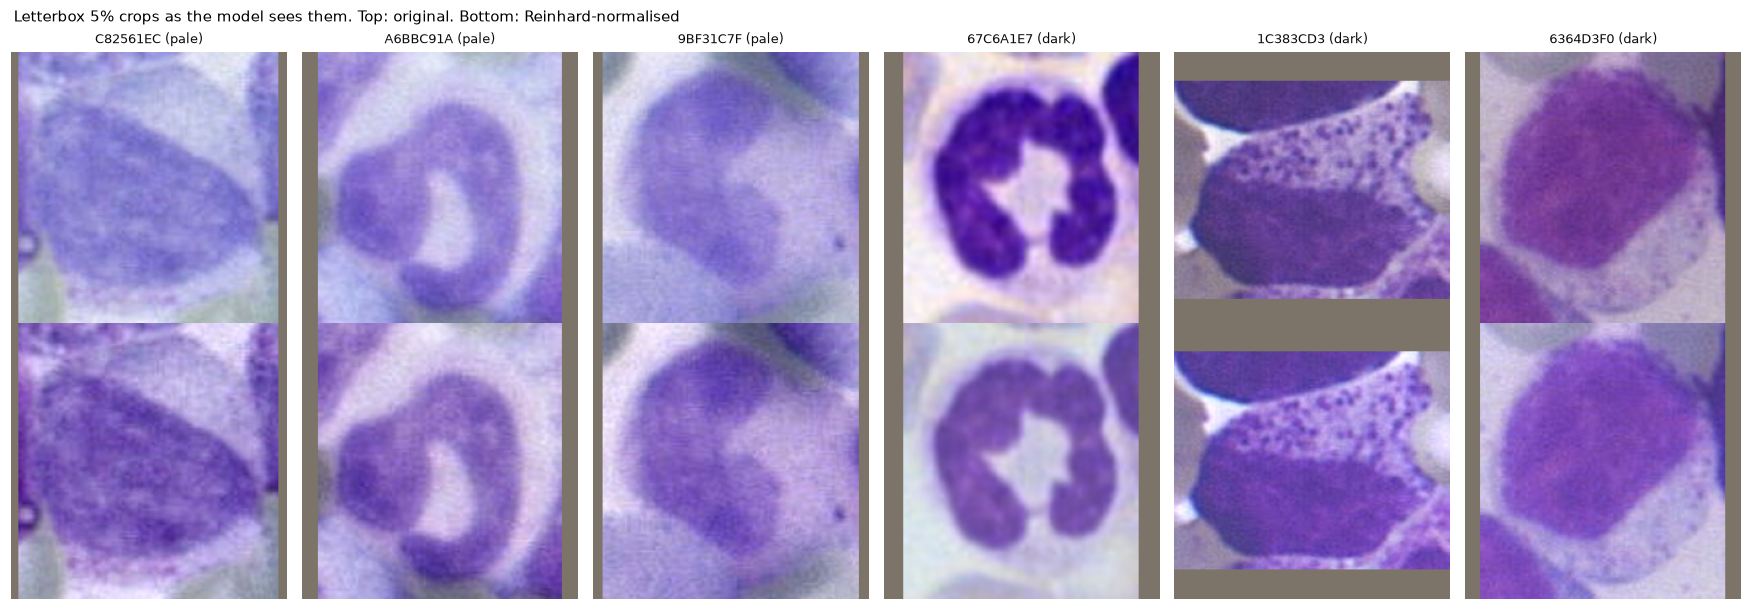

In [7]:
stats_p = {}
for p, (s1, s2, n) in acc.items():
    mu = s1 / n
    stats_p[p] = (mu, np.sqrt(s2 / n - mu ** 2))
mu_all = np.array([v[0] for v in stats_p.values()])
sd_all = np.array([v[1] for v in stats_p.values()])
TARGET_MU, TARGET_SD = np.median(mu_all, 0), np.median(sd_all, 0)
print("target mean L,a,b:", TARGET_MU.round(2), "| target SD:", TARGET_SD.round(2))
print("per-patient mean L range:", mu_all[:, 0].min().round(1), "-", mu_all[:, 0].max().round(1))


def reinhard(img, p):
    mu, sd = stats_p[p]
    lab = rgb_to_lab(np.asarray(img).astype(float))
    lab = (lab - mu) / sd * TARGET_SD + TARGET_MU
    return Image.fromarray(lab_to_rgb(lab))


fig, axes = plt.subplots(2, 6, figsize=(16, 5.6))
for j, p in enumerate(show):
    c = cells[cells["patient_id"] == p].sample(1, random_state=3).iloc[0]
    img = Image.open(c["path"]).convert("RGB")
    axes[0, j].imshow(tight_letterbox(img, c)); axes[1, j].imshow(tight_letterbox(reinhard(img, p), c))
    axes[0, j].set_title(f"{p[:8]} ({'pale' if j < 3 else 'dark'})", fontsize=8.5)
for ax in axes.ravel():
    ax.axis("off")
fig.suptitle("Letterbox 5% crops as the model sees them. Top: original. Bottom: Reinhard-normalised",
             x=0.01, ha="left", fontsize=9.5)
plt.tight_layout()
plt.show()

In [8]:
import torch
import torch.nn as nn
import torchvision.transforms.functional as TF
from torchvision import transforms

hub_dir = Path.home() / ".cache" / "torch" / "hub" / "facebookresearch_dinov2_main"
model = torch.hub.load(str(hub_dir), "dinov2_vitb14", source="local", pretrained=False)
teacher = torch.load(ROOT / "models" / "DinoBloom-B.pth", map_location="cpu", weights_only=True)["teacher"]
weights = {k.replace("backbone.", ""): v for k, v in teacher.items()
           if "dino_head" not in k and "ibot_head" not in k}
model.pos_embed = nn.Parameter(torch.zeros(1, 257, 768))
print(model.load_state_dict(weights, strict=True))
model.eval()
for prm in model.parameters():
    prm.requires_grad_(False)
device = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
model = model.to(device)
norm = transforms.Compose([transforms.ToTensor(),
                           transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])


def embed(make_img, rows=None, batch=64, label=""):
    rows = range(N) if rows is None else rows
    rows = list(rows)
    out, t0 = [], time.time()
    with torch.no_grad():
        for s in range(0, len(rows), batch):
            idx = rows[s:s + batch]
            x = torch.stack([norm(make_img(j)) for j in idx]).to(device)
            out.append(model(x).cpu())
            if (s // batch) % 40 == 0:
                print(f"  {label} {s + len(idx)} / {len(rows)}  {time.time() - t0:.0f} s", flush=True)
    return torch.cat(out).numpy()


def load_crop(j):
    return Image.open(cells.at[j, "path"]).convert("RGB")


# Sanity: the unnormalised pipeline must reproduce the saved baseline embeddings
base_cls = np.load(EMB / BASE / "emb_cls.npy")
rep = embed(lambda j: tight_letterbox(load_crop(j), cells.loc[j]), rows=range(64), label="sanity")
cos = (rep * base_cls[:64]).sum(1) / (np.linalg.norm(rep, axis=1) * np.linalg.norm(base_cls[:64], axis=1))
print(f"Reproduce saved letterbox_m05 embeddings (64 cells): min cosine {cos.min():.6f}")
assert cos.min() > 0.9999

/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


<All keys matched successfully>


  sanity 64 / 64  3 s


Reproduce saved letterbox_m05 embeddings (64 cells): min cosine 1.000000


In [9]:
def save_folder(folder, cls, note):
    folder.mkdir(exist_ok=False)
    np.save(folder / "emb_cls.npy", cls.astype(np.float32))
    json.dump({"created": datetime.datetime.now().isoformat(timespec="seconds"),
               "model": "DinoBloom-B (frozen, teacher backbone), weights md5 03e64e849bfb383f8400e2c95166f32c",
               "crop": "letterbox, margin 0.05, from stored 320x320 crops (as dinobloom_b_letterbox_m05)",
               "colour": note, "rows": "same order as dinobloom_b/cells.csv (embedding_row)",
               "labels_used_for_embedding": False, "n_cells": int(len(cls)), "device": str(device),
               "created_by": "notebooks/stain_normalization.ipynb"},
              open(folder / "provenance.json", "w"), indent=2)


# Part 2: Reinhard-normalised embeddings
if (NEW["reinhard"] / "emb_cls.npy").exists():
    X_rh = np.load(NEW["reinhard"] / "emb_cls.npy")
    print("loaded", NEW["reinhard"].name, X_rh.shape)
else:
    X_rh = embed(lambda j: tight_letterbox(reinhard(load_crop(j), pid[j]), cells.loc[j]), label="reinhard")
    save_folder(NEW["reinhard"], X_rh,
                "Reinhard per patient: CIELAB mean/SD of non-background pixels outside the annotated boxes "
                f"-> cohort median target mean {TARGET_MU.round(3).tolist()}, sd {TARGET_SD.round(3).tolist()}")
    print("saved", NEW["reinhard"])

  reinhard 64 / 8340  5 s


  reinhard 2624 / 8340  621 s


  reinhard 5184 / 8340  776 s


  reinhard 7744 / 8340  983 s


saved /Users/abishekchozhan/Documents/projects/peds_heme_onc/peds-leukemia/data/embeddings/dinobloom_b_letterbox_m05_reinhard


## 3. Colour-jitter averaging
4 random colour perturbations per cell (brightness, contrast, saturation ×0.8–1.2; hue ±0.03), CLS averaged.

  jitter 1/4 64 / 8340  2 s


  jitter 1/4 2624 / 8340  76 s


  jitter 1/4 5184 / 8340  127 s


  jitter 1/4 7744 / 8340  177 s


  jitter 2/4 64 / 8340  1 s


  jitter 2/4 2624 / 8340  52 s


... (7 outputs left out)

  jitter 4/4 2624 / 8340  51 s


  jitter 4/4 5184 / 8340  101 s


  jitter 4/4 7744 / 8340  151 s


saved /Users/abishekchozhan/Documents/projects/peds_heme_onc/peds-leukemia/data/embeddings/dinobloom_b_letterbox_m05_jitter4


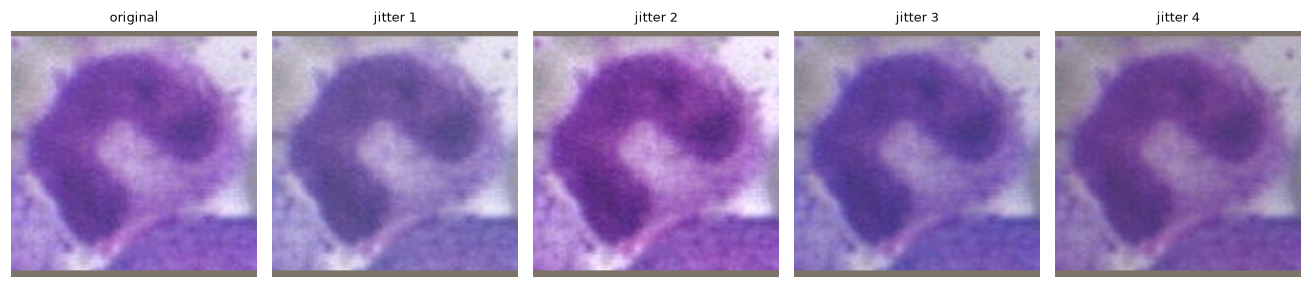

In [10]:
def jittered(j, d):
    r = np.random.default_rng([d, j])
    b, c_, s = r.uniform(0.8, 1.2, 3)
    h = r.uniform(-0.03, 0.03)
    img = load_crop(j)
    img = TF.adjust_brightness(img, b)
    img = TF.adjust_contrast(img, c_)
    img = TF.adjust_saturation(img, s)
    img = TF.adjust_hue(img, h)
    return tight_letterbox(img, cells.loc[j])


if (NEW["jitter4"] / "emb_cls.npy").exists():
    X_jt = np.load(NEW["jitter4"] / "emb_cls.npy")
    print("loaded", NEW["jitter4"].name, X_jt.shape)
else:
    X_jt = np.mean([embed(lambda j: jittered(j, d), label=f"jitter {d + 1}/{N_JITTER}") for d in range(N_JITTER)], 0)
    save_folder(NEW["jitter4"], X_jt,
                f"mean CLS over {N_JITTER} colour jitters of the stored 320 px crop: brightness/contrast/saturation "
                "U(0.8,1.2), hue U(-0.03,0.03), numpy seed [draw, row]")
    print("saved", NEW["jitter4"])

fig, axes = plt.subplots(1, 5, figsize=(12, 2.6))
axes[0].imshow(tight_letterbox(load_crop(0), cells.loc[0])); axes[0].set_title("original", fontsize=8.5)
for d in range(N_JITTER):
    axes[d + 1].imshow(jittered(0, d)); axes[d + 1].set_title(f"jitter {d + 1}", fontsize=8.5)
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

## 4. Trajectory checks on baseline vs. the two fixes
Same procedure as `reports/scripts/analyze_variants.py`: L2-normalise → PCA (50 components) → diffusion map
(k = 15) → DC1 oriented by stage (the only use of labels) → Option A pseudotime. The baseline must reproduce the saved
pseudotime.

In [11]:
def rho(a, b):
    return float(stats.spearmanr(a, b).statistic)


def diffusion_map(Y, k=15, n_eig=6, seed=0):
    n = len(Y)
    d, nbr = NearestNeighbors(n_neighbors=k + 1).fit(Y).kneighbors(Y)
    d, nbr = d[:, 1:], nbr[:, 1:]
    sigma = d[:, -1]
    ri = np.repeat(np.arange(n), k)
    cj = nbr.ravel()
    w = np.exp(-d.ravel() ** 2 / (sigma[ri] * sigma[cj]))
    W = csr_matrix((w, (ri, cj)), shape=(n, n))
    W = W.maximum(W.T)
    q = np.asarray(W.sum(axis=1)).ravel()
    Wt = diags(1 / q) @ W @ diags(1 / q)
    rs = np.asarray(Wt.sum(axis=1)).ravel()
    M = diags(rs ** -0.5) @ Wt @ diags(rs ** -0.5)
    vals, vecs = eigsh(M, k=n_eig, which="LA", v0=np.random.default_rng(seed).random(n))
    o = np.argsort(vals)[::-1]
    return vals[o], (vecs[:, o] * (rs ** -0.5)[:, None])[:, 1:]


prows = [g.index.to_numpy() for _, g in cells.groupby("patient_id")]
crowd = cells["crowding_outside"].to_numpy()
dark = cells["stain_darkness"].to_numpy()


def centre_within(x):
    return x - pd.Series(x).groupby([pid, stage]).transform("mean").to_numpy()


def analyze(X):
    r = {}
    Xn = X / np.linalg.norm(X, axis=1)[:, None]
    Z = PCA(n_components=50, random_state=0).fit_transform(Xn)
    nb = NearestNeighbors(n_neighbors=16).fit(Z).kneighbors(Z, return_distance=False)[:, 1:]
    r["same_patient_nbrs"] = (pid[nb] == pid[:, None]).mean()
    largest = []
    for k in (10, 15, 30):
        A = kneighbors_graph(Z, n_neighbors=k, include_self=False)
        _, comp = connected_components(A.maximum(A.T), directed=False)
        largest.append(np.bincount(comp).max() / N)
    r["S1_min_largest"] = min(largest)
    r["S1_pass"] = min(largest) >= 0.99
    evals, DC = diffusion_map(Z, k=15, n_eig=16)
    r["DC1_eig"], r["DC2_eig"] = evals[1], evals[2]
    r["S4_pass"] = int((evals[1:] > 0.98).sum()) <= 1
    r["S2_R2_patient_DC1"] = r2_by_group(DC[:, 0], pid)
    r["S2_pass"] = r["S2_R2_patient_DC1"] < 0.5
    dc1 = DC[:, 0] * np.sign(rho(DC[:, 0], stage))
    pt = (dc1 - dc1.min()) / (dc1.max() - dc1.min())
    med = pd.Series(pt).groupby(stage).median()
    r["V2_rho"] = rho(dc1, stage)
    r["V2_monotonic"] = bool(med.is_monotonic_increasing)
    v3 = [rho(dc1[i], stage[i]) for i in prows]
    r["V3_n_pos"] = int(np.sum(np.array(v3) > 0))
    r["V3_median_rho"] = float(np.median(v3))
    r["V3_min_rho"] = float(np.min(v3))
    ci, nj = np.repeat(np.arange(N), 15), nb.ravel()

    def adj_share(s):
        gap = np.abs(s[ci] - s[nj])
        return (gap[gap > 0] == 1).mean()

    rng = np.random.default_rng(0)
    null = []
    for _ in range(200):
        sh = stage.copy()
        for i in prows:
            sh[i] = rng.permutation(stage[i])
        null.append(adj_share(sh))
    r["V1_adj"], r["V1_null_max"] = adj_share(stage), max(null)
    r["V1_pass"] = r["V1_adj"] > r["V1_null_max"]
    r["rho_DC1_area"] = rho(dc1, area)
    disc = centre_within(pt - pd.Series(pt).groupby(stage).transform("median").to_numpy())
    for name, x in (("crowding", crowd), ("stain_dark", dark)):
        xc = centre_within(x)
        r[f"ctx_{name}_Seg"] = rho(xc[stage == 5], disc[stage == 5])
        r[f"ctx_{name}_median"] = float(np.median([rho(xc[stage == s], disc[stage == s]) for s in range(1, 6)]))
    r["stage_medians"] = np.round(med.to_numpy(), 3).tolist()
    return r, pt


EMBS = {"baseline (letterbox 5%)": base_cls, "Reinhard": X_rh, "colour-jitter x4": X_jt}
RES, PT = {}, {}
for name, X in EMBS.items():
    t0 = time.time()
    RES[name], PT[name] = analyze(X)
    print(f"{name}: {time.time() - t0:.0f} s")
print("baseline reproduces saved pseudotime: rho =", round(rho(PT["baseline (letterbox 5%)"], base_pt), 5))
assert rho(PT["baseline (letterbox 5%)"], base_pt) > 0.999
summary = pd.DataFrame(RES)
summary

baseline (letterbox 5%): 1 s


Reinhard: 1 s


colour-jitter x4: 1 s
baseline reproduces saved pseudotime: rho = 1.0


,baseline (letterbox 5%),Reinhard,colour-jitter x4
same_patient_nbrs,0.290296,0.278993,0.292102
S1_min_largest,1.0,1.0,1.0
S1_pass,True,True,True
DC1_eig,0.979082,0.979388,0.979128
DC2_eig,0.917812,0.91743,0.917444
S4_pass,True,True,True
S2_R2_patient_DC1,0.045639,0.045316,0.045673
S2_pass,True,True,True
V2_rho,0.904642,0.90419,0.904576
V2_monotonic,True,True,True


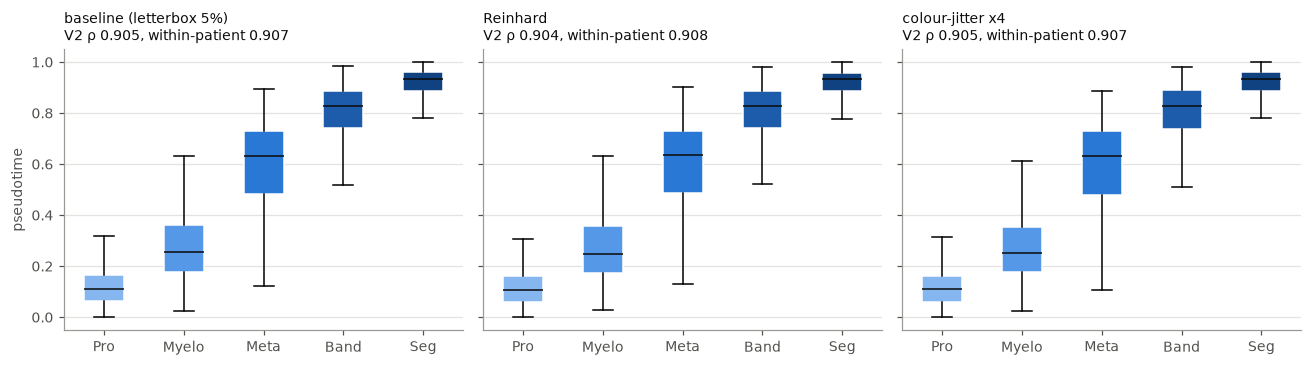

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for ax, (name, pt) in zip(axes, PT.items()):
    bp = ax.boxplot([pt[stage == s] for s in range(1, 6)], showfliers=False, patch_artist=True,
                    medianprops={"color": INK})
    for b, col in zip(bp["boxes"], STAGE_COLORS):
        b.set(facecolor=col, edgecolor="white")
    ax.set_xticks(range(1, 6), SHORT)
    ax.grid(axis="y", color=GRID)
    ax.set_title(f"{name}\nV2 ρ {RES[name]['V2_rho']:.3f}, within-patient {RES[name]['V3_median_rho']:.3f}",
                 loc="left", fontsize=9)
axes[0].set_ylabel("pseudotime")
plt.tight_layout()
plt.show()

### Does the per-patient offset still follow staining?

In [13]:
IDXS = ["stain_darkness", strongest] + [k for k in SLIDE_IDX if k != strongest] + ["cell_nuc_L"]
rows = []
FEATS = {}
for name, pt in PT.items():
    F = pt_features(pt)
    FEATS[name] = F
    for k in IDXS:
        rows.append({"version": name, "vs": k, **spearman_ci(F["offset"], S[k])})
    rows.append({"version": name, "vs": "box area (µm²)", **spearman_ci(F["offset"], area_p)})
off = pd.DataFrame(rows)
tab = off.pivot(index="vs", columns="version", values="rho")[list(PT)].round(2)
print("Spearman rho of the per-patient offset with each index (n = 46):")
print(tab.to_string())

b = RES["baseline (letterbox 5%)"]
crit = []
for name in ["Reinhard", "colour-jitter x4"]:
    r = RES[name]
    c1 = r["S1_pass"] and r["S2_pass"] and r["S4_pass"] and r["V1_pass"] and r["V2_monotonic"] and r["V3_n_pos"] > 23
    c2 = (r["V2_rho"] >= b["V2_rho"] - 0.02) and (r["V3_median_rho"] >= b["V3_median_rho"] - 0.02)
    c3 = abs(tab.loc["stain_darkness", name]) < 0.3 and abs(tab.loc[strongest, name]) < 0.3
    crit.append({"version": name, "1 checks pass": c1, "2 ordering kept": c2,
                 "3 offset decoupled from stain": c3, "fix succeeds": c1 and c2 and c3})
pd.DataFrame(crit)

Spearman rho of the per-patient offset with each index (n = 46):
version         baseline (letterbox 5%)  Reinhard  colour-jitter x4
vs                                                                 
bg_L                               0.24      0.24              0.29
box area (µm²)                    -0.43     -0.40             -0.43
cell_nuc_L                         0.65      0.66              0.66
nbr_nuc_L                          0.61      0.61              0.61
ref_L                              0.16      0.17              0.17
ref_b                             -0.36     -0.39             -0.35
stain_darkness                    -0.61     -0.62             -0.62


,version,1 checks pass,2 ordering kept,3 offset decoupled from stain,fix succeeds
0,Reinhard,True,True,False,False
1,colour-jitter x4,True,True,False,False


## 5. Lab tests on each version
H1a: WBC vs median pseudotime (expected ρ < 0). H2-WBC: WBC vs stage-adjusted offset. n = 39 patients with WBC.

In [14]:
lab = pd.read_csv(LAB_CSV, dtype={"patient_id": str}).set_index("patient_id")
lab = lab.rename(columns=lambda c: c.split(" (")[0]).astype(float)
rows = []
for name, F in FEATS.items():
    for f in ["pt_median", "offset"]:
        rows.append({"version": name, "feature": f, **spearman_ci(F[f], lab["WBC"])})
pd.DataFrame(rows).round(3)

,version,feature,n,rho,ci_lo,ci_hi,p
0,baseline (letterbox 5%),pt_median,39,-0.176,-0.492,0.154,0.285
1,baseline (letterbox 5%),offset,39,-0.045,-0.425,0.313,0.786
2,Reinhard,pt_median,39,-0.190,-0.496,0.137,0.245
3,Reinhard,offset,39,-0.067,-0.440,0.284,0.686
4,colour-jitter x4,pt_median,39,-0.175,-0.482,0.151,0.286
5,colour-jitter x4,offset,39,-0.050,-0.415,0.296,0.762


## 6. Summary (2026-11-09 run)

**Neither fix worked, and the reason is informative: the model is already almost blind to colour.**

| | baseline | Reinhard | colour-jitter ×4 |
|---|---|---|---|
| Cosine similarity to baseline embeddings (median / 5th pct) | 1 | 0.997 / 0.983 | 0.998 / 0.988 |
| *for scale: square 5% crop vs letterbox 5%* | | *0.936 / 0.831* | |
| All checks pass; V2 ρ; V3 median ρ | yes; 0.905; 0.907 | yes; 0.904; 0.908 | yes; 0.905; 0.907 |
| Offset vs old `stain_darkness` | −0.61 | −0.62 | −0.62 |
| Offset vs neighbour-nucleus lightness | +0.61 | +0.61 | +0.61 |
| Offset vs box area | −0.43 | −0.40 | −0.43 |
| WBC vs median pseudotime (n = 39) | −0.18 (p 0.29) | −0.19 (p 0.25) | −0.18 (p 0.29) |
| WBC vs offset | −0.05 (p 0.79) | −0.07 (p 0.69) | −0.05 (p 0.76) |

**What Part 1 showed**
- There *is* a slide-level effect by the pre-set rule: the offset tracks the lightness of **neighbouring** nuclei
  (ρ = +0.61), not just of the annotated cell. At patient level the two are almost the same number (ρ = 0.99), so
  "how dark the nuclei stain on this slide" is a genuine slide property.
- The neutral reference (mostly red cells) and the background barely relate to the offset (|ρ| ≤ 0.24 for lightness;
  ρ = −0.36 for blue–yellow tint).

**What Parts 2–4 showed**
- Reinhard visibly equalised the slides (per-slide mean lightness 54.7–70.2 → 61.7), yet the embeddings moved
  less than 1% and every result is unchanged. Colour jitter likewise. DinoBloom was trained with heavy colour
  augmentation, so it largely ignores global colour already.
- Therefore the offset–darkness link is **not carried by colour as the model sees it**. It must come from something
  that differs between slides *and* co-varies with nuclear stain intensity: most plausibly **smear preparation**
  (thick areas: cells spread less, look smaller and denser, and stain darker), plus box-drawing style (box area ρ = −0.43).
  These are shape/texture differences, which colour normalisation cannot remove. A biological contribution (patients
  whose cells truly have denser chromatin) also cannot be excluded.

**Pre-set verdict:** criteria 1 and 2 met, criterion 3 failed for both → neither fix succeeds. Lab results unchanged.

**Next options**
1. Measure smear thickness / cell spreading per slide (e.g. red-cell size and overlap, cell density) and test it
   against the offset, the way Part 1 tested colour.
2. Treat the offset as confounded by slide preparation and stop using it as a biomarker; keep median pseudotime
   (which the staining issue affects less: ρ with old darkness −0.38).
3. Within-slide comparisons only (e.g. cells in thin vs thick regions of the same smear) to separate preparation from patient biology.